In [7]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

import os
halogen_dir = os.getcwd()
os.chdir('../')
from edautils.plot import ternary_ax, ternary
from edautils.plot import calc_portion, energy_bar_ax
from edautils.plot import grouped_boxplot_ax, box_plot_data
from edautils.plot import kdeplot, kdeplot_norm
from edautils.plot import plot

os.chdir(halogen_dir)
df = pd.read_csv('pi_cation_EDA.csv', index_col=0)
# df = raw_df.query('TOTAL < 0')
df.shape

(1531, 40)

In [8]:
print(len(df.query('TOTAL > 0'))) 
print(len(df.query('TOTAL < 0')))

19
1512


In [9]:
plot?

Signature:
plot(
    type,
    args,
    dfs,
    ax,
    cmap_range=[-100, 0.0],
    median=False,
    ratio1=False,
    ratio2=False,
    plot=False,
    kde_norm=False,
)
Docstring:
General Plot Function

Parameters
----------
type: {'ternary', 'bar', 'dist', 'box'}
    Plot types
args: list
    List of arguments for each plot type:
    - 'ternary': (label, index, type, cmap_range)
        - label: str
            type of atom/interaction
        - index: str
            index for ternary plot
        - type: str
            type of ternary plot ('frz_orb_disp', 'elec_orb_disp', 'frz_pol_ct')
    - 'bar': (labels, items)
        - label: list(str)
            type of atom/interaction
        - items: list(str)
            EDA energy components 
    - 'dist': (column, labels, item, palette)
        - column: str
            column of dataframe
        - label: list(str)
            type of atom/interaction
        - item: list(str)
            EDA energy components
        - palette:

In [10]:
restype_count = df['restype'].value_counts()
lig_group_count = df['lig_group'].value_counts()
print(restype_count)
print(lig_group_count)

len(df.query("restype == 'HIS' and protcharged == False"))

restype
ARG    642
LYS    472
TRP    171
TYR    147
PHE     61
HIS     38
Name: count, dtype: int64
lig_group
Aromatic      1114
quartamine     152
tertamine      142
guanidine      115
sulfonium        8
Name: count, dtype: int64


38

# Heteroatom vs Pure Aromatic

# Classification

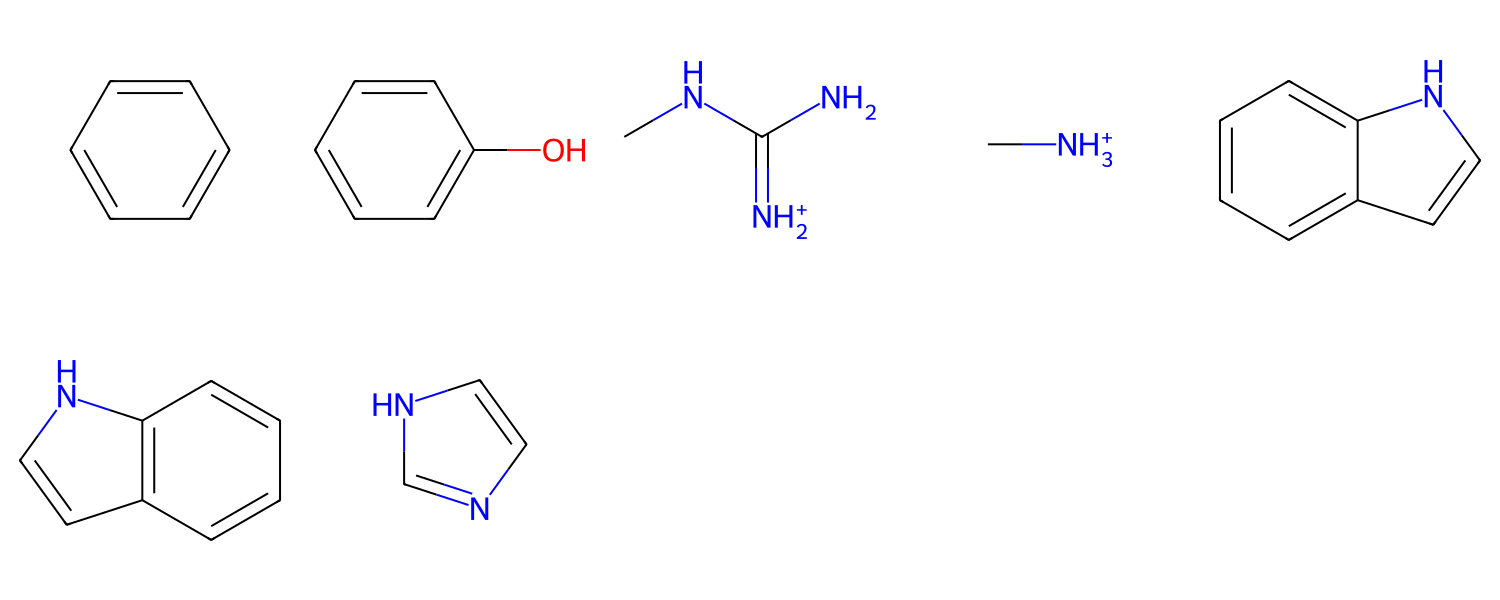

In [11]:
from rdkit import Chem
from rdkit.Chem import rdmolops, AllChem, Draw
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

df_aromatic_prot = df.query("protcharged == False")

hetratom_prot = []
aromatic_prot = []


for index, row in df_aromatic_prot.iterrows():
    if row['restype'] == 'HIS' or row['restype'] == 'TRP':
        hetratom_prot.append(index)
    if row['restype'] == 'TYR' or row['restype'] == 'PHE':
        aromatic_prot.append(index)


Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in set(df['smiles1'])], subImgSize=(300, 300), molsPerRow=5)


In [12]:
from edautils.fragment import find_rings_old

dataset_dir = '/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset'

df_aromatic_lig = df.query("protcharged == True")

hetratom_lig = []
aromatic_lig = []

hetrato_atoms = []
aromatic_atoms = []

errs = []

for index, row in df_aromatic_lig.iterrows():
    aromatic = True
    temp_atomlist = []
    ligand = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_ligand_refined.sdf")
    mol = Chem.SDMolSupplier(ligand, removeHs=False, sanitize=True)[0]
    ring_list = find_rings_old(mol, find_hetero_rings=False, find_small_rings=False) # only aromatic rings, idx numbers in OpenBabel 1 lower than Plip

    lig_idx_list = row['lig_idx_list'].split()
    lig_idx_set = set([int(id) - 1 for id in lig_idx_list])
    ring_temp = [s for s in ring_list if lig_idx_set & s]
    
    try:
        for idx in ring_temp[0]:
            atom = mol.GetAtomWithIdx(idx)
            symbol = atom.GetSymbol()
            temp_atomlist.append(symbol)
            if not symbol == 'C':
                aromatic = False

        if aromatic:
            aromatic_lig.append(index)
            aromatic_atoms.append((index, temp_atomlist)) # keep the list of atoms
        else:
            hetratom_lig.append(index)
            hetrato_atoms.append((index, temp_atomlist)) # keep the list of atoms
    except Exception as e:
        for idx in lig_idx_set:
            atom = mol.GetAtomWithIdx(idx)
            symbol = atom.GetSymbol()
            temp_atomlist.append(symbol)
        errs.append([index, temp_atomlist])

print(len(aromatic_lig))
print(len(hetratom_lig))

errPDBID = [err[0] for err in errs]
errs

577
526


[['1m74_495_LYS_7847_11-17', ['C', 'O', 'C', 'C', 'C']],
 ['1lke_55_ARG_899-905_2-6', ['C', 'C', 'O', 'C', 'C']],
 ['4oma_210_LYS_3138_17-22', ['C', 'C', 'N', 'O', 'C']],
 ['5a3r_175_ARG_2826-2832_18-43', ['C', 'C', 'C', 'C', 'C', 'C']],
 ['4hco_169_LYS_2721_1-6', ['C', 'C', 'C', 'C', 'C', 'C']],
 ['2wf0_223_ARG_3539-3545_24-28', ['C', 'C', 'C', 'N', 'C']],
 ['2wez_223_ARG_3539-3545_24-28', ['C', 'C', 'C', 'N', 'C']],
 ['4h71_171_LYS_2746_3-8', ['C', 'C', 'C', 'C', 'C', 'C']],
 ['1lnm_55_ARG_897-903_2-6', ['C', 'C', 'O', 'C', 'C']],
 ['6npf_350_LYS_5199_5-11', ['C', 'C', 'C', 'N', 'C']],
 ['5i59_245_ARG_3935-3941_6-26', ['C', 'C', 'C', 'S', 'N']]]

# Protein and ligand combined

# Ternary Plots

785
735
pure atomatic protein: 208
heteroatom protein: 209
pure atomatic ligand: 577
heteroatom ligand: 526


/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_19096/1647751719.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_19096/1647751719.py:52: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_19096/1647751719.py:68: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


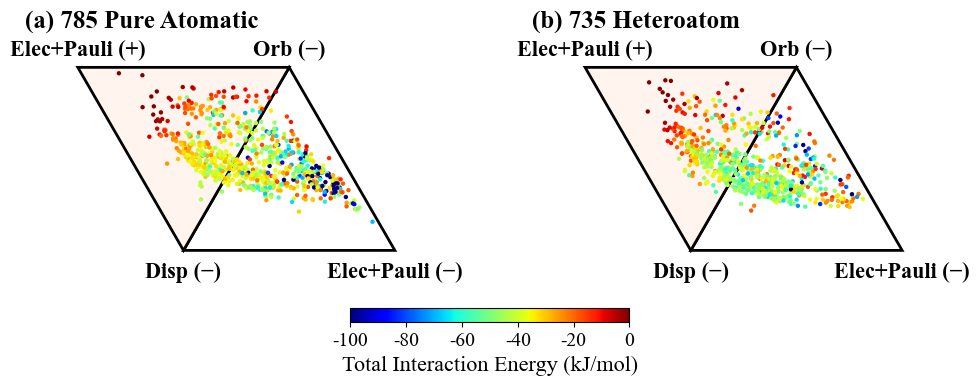

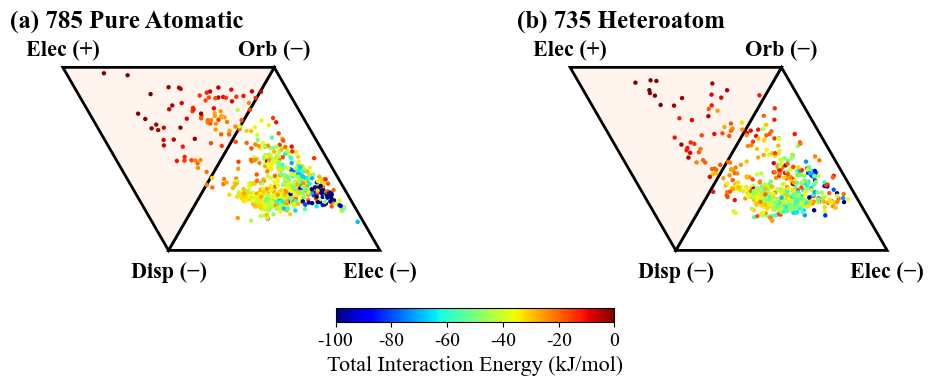

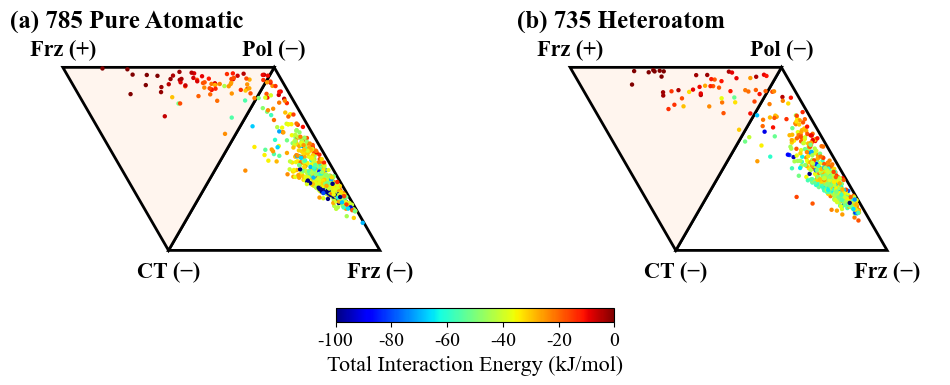

In [25]:
aromatic = aromatic_prot + aromatic_lig
df_aromatic = df.loc[aromatic]

hetratom = hetratom_prot + hetratom_lig
df_hetratom = df.loc[hetratom]

print(len(aromatic))
print(len(hetratom))

print(f'pure atomatic protein: {len(aromatic_prot)}')
print(f'heteroatom protein: {len(hetratom_prot)}')

print(f'pure atomatic ligand: {len(aromatic_lig)}')
print(f'heteroatom ligand: {len(hetratom_lig)}')


dfs = [df_aromatic, df_hetratom]
labels = ['Pure Atomatic', 'Heteroatom']

cmap_range = [-100, 0]
type = 'frz_orb_disp'

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sc = plot('ternary', (labels[0], 'a', type), dfs[0], axes[0], cmap_range)
plot('ternary', (labels[1], 'b', type), dfs[1], axes[1], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
plt.savefig("Visualizations/ternary_1.png")

type = 'elec_orb_disp'

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sc = plot('ternary', (labels[0], 'a', type), dfs[0], axes[0], cmap_range)
plot('ternary', (labels[1], 'b', type), dfs[1], axes[1], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')

type = 'frz_pol_ct'

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sc = plot('ternary', (labels[0], 'a', type), dfs[0], axes[0], cmap_range)
plot('ternary', (labels[1], 'b', type), dfs[1], axes[1], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
plt.savefig("Visualizations/ternary_2.png")


## Bar Plot Ratio type formulation

### ratio1: $R_1 = \frac{\sum_{i} E_{i}^{(t)}}{\sum_{i} E_{i}^{(\text{total})}}$

### ratio2: $R_2 = \sum_{i} \frac{E_{i}^{(t)}}{E_{i}^{(\text{total})}}$

len: [147, 61]
len: [147, 61]


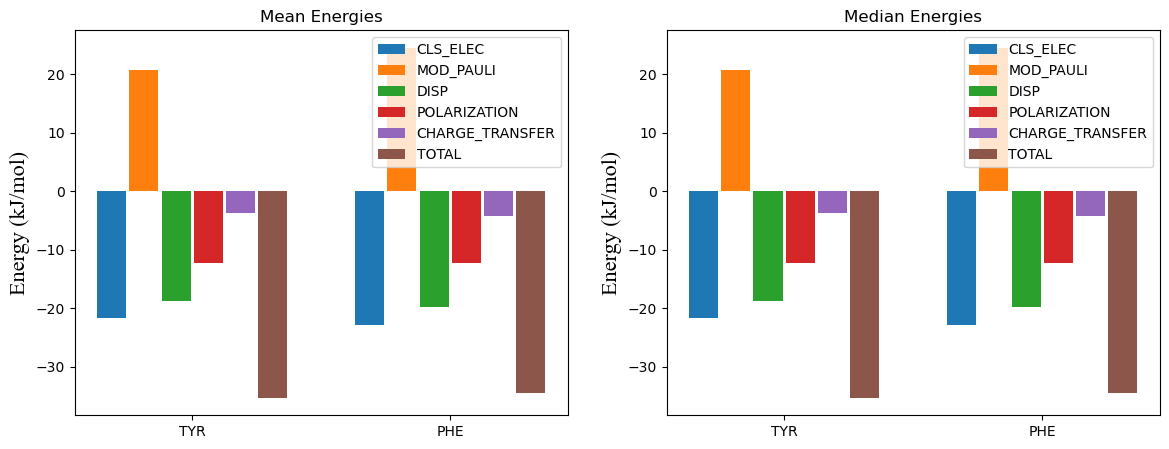

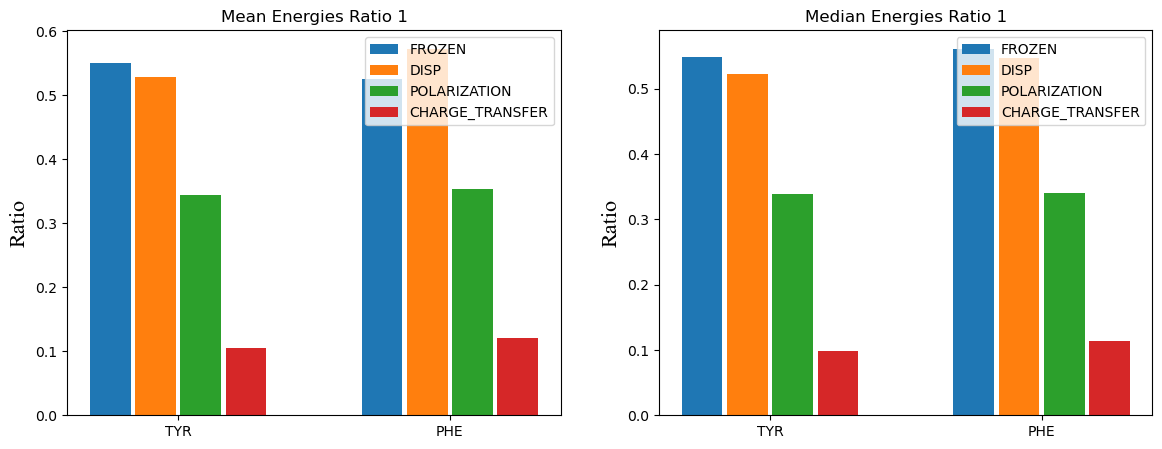

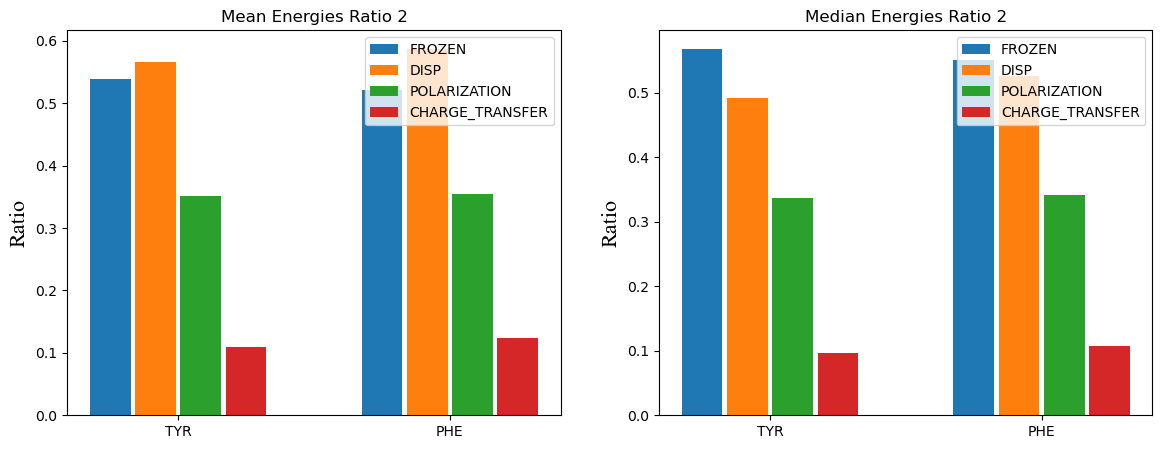

In [24]:
items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]

print(f'len: {list(map(len, dfs))}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), dfs, axes[0])
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), dfs, axes[1], median=False)
axes[1].set_title('Median Energies')
plt.savefig("bar_energy.png")

items = [
    'FROZEN', 
    # 'CLS_ELEC', 
    # 'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    # 'TOTAL'
]

print(f'len: {list(map(len, dfs))}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), dfs, axes[0], ratio1=True)
axes[0].set_title('Mean Energies Ratio 1')
plot('bar', (labels, items), dfs, axes[1], median=True, ratio1=True)
axes[1].set_title('Median Energies Ratio 1')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), dfs, axes[0], ratio2=True)
axes[0].set_title('Mean Energies Ratio 2')
plot('bar', (labels, items), dfs, axes[1], median=True, ratio2=True)
axes[1].set_title('Median Energies Ratio 2')
plt.savefig("bar_energy_ratio.png")



# Seperate Protein Ligand

len: [208, 209, 577, 526]
len: [208, 209, 577, 526]


Text(0.5, 1.0, 'Median Energies')

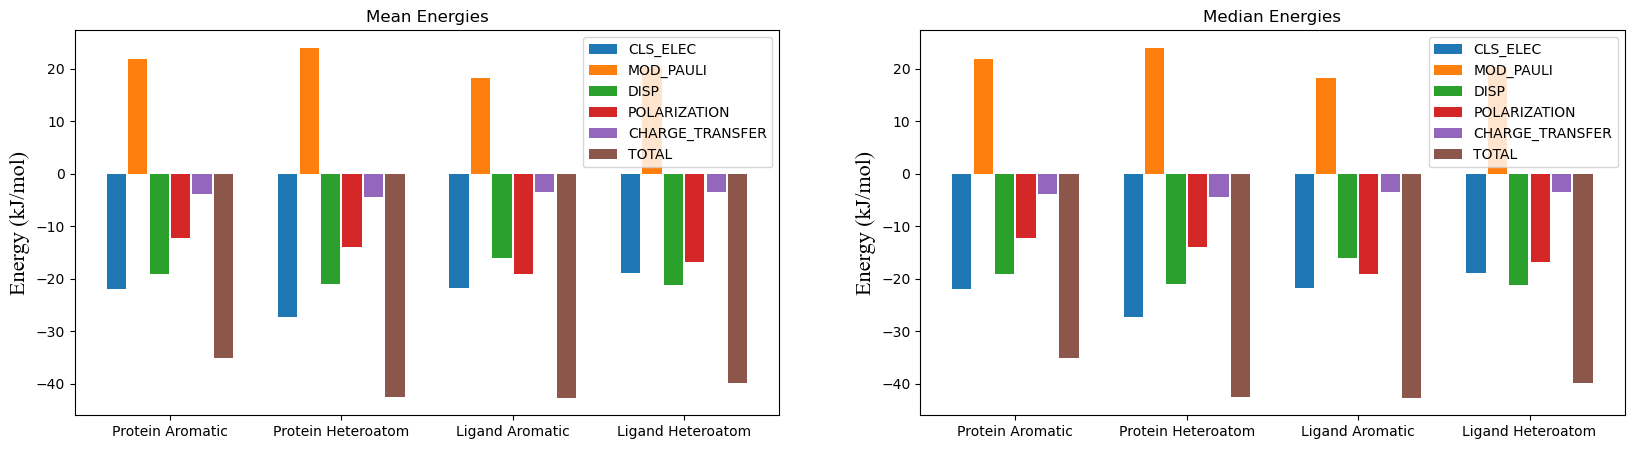

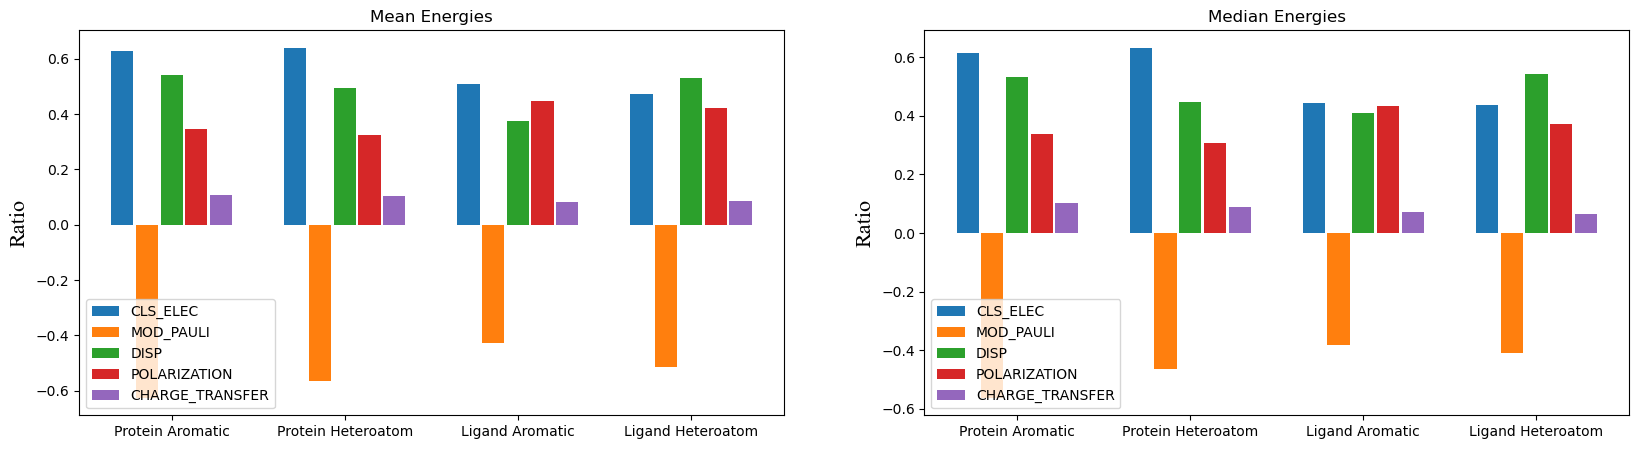

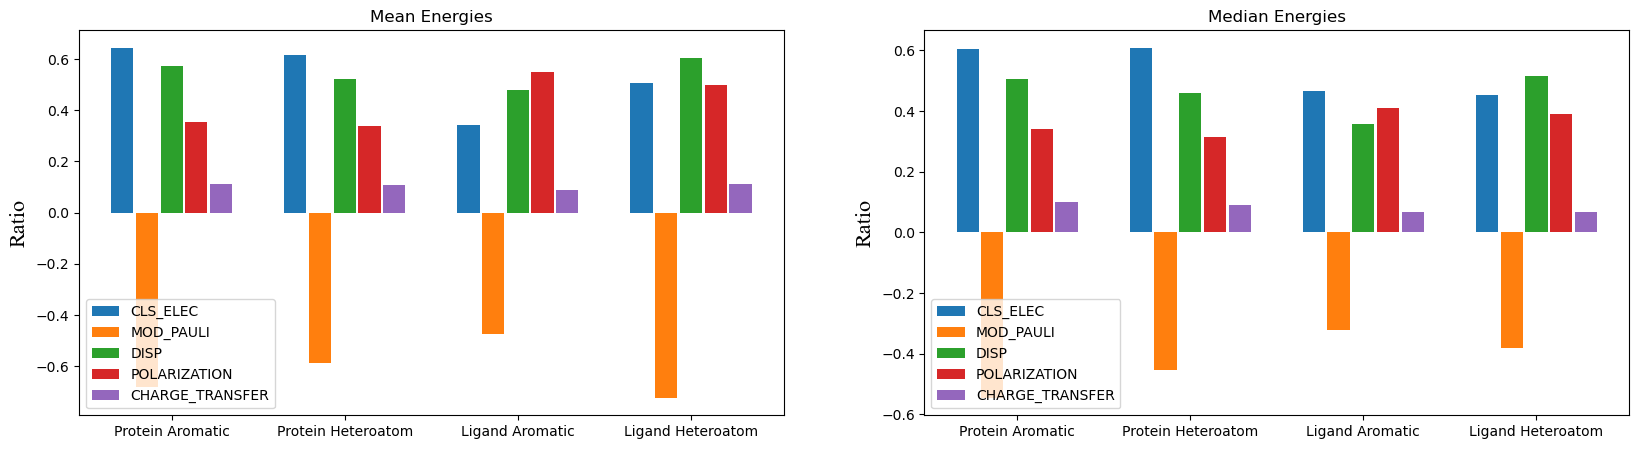

In [15]:
df_aromatic_prot = df.loc[aromatic_prot]
df_hetratom_prot = df.loc[hetratom_prot]
df_aromatic_lig = df.loc[aromatic_lig]
df_hetratom_lig = df.loc[hetratom_lig]

dfs = [df_aromatic_prot, df_hetratom_prot, df_aromatic_lig, df_hetratom_lig]
labels = ['Protein Aromatic', 'Protein Heteroatom', 'Ligand Aromatic', 'Ligand Heteroatom', ]

items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]

print(f'len: {list(map(len, dfs))}')
print(f'len: {list(map(len, dfs))}')

fig, axes = plt.subplots(1, 2, figsize=(20, 5))
plot('bar', (labels, items), dfs, axes[0], median=False)
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), dfs, axes[1])
axes[1].set_title('Median Energies')

items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    # 'TOTAL'
]

fig, axes = plt.subplots(1, 2, figsize=(20, 5))
plot('bar', (labels, items), dfs, axes[0], ratio1=True)
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), dfs, axes[1], median=True, ratio1=True)
axes[1].set_title('Median Energies')

fig, axes = plt.subplots(1, 2, figsize=(20, 5))
plot('bar', (labels, items), dfs, axes[0], ratio2=True)
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), dfs, axes[1], median=True, ratio2=True)
axes[1].set_title('Median Energies')

len: [209, 526]
len: [208, 577]


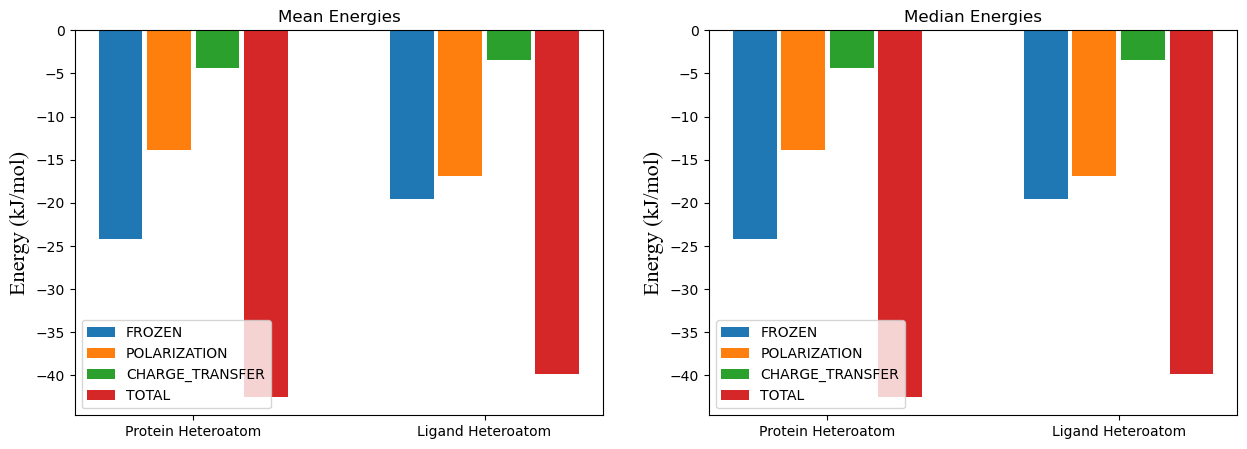

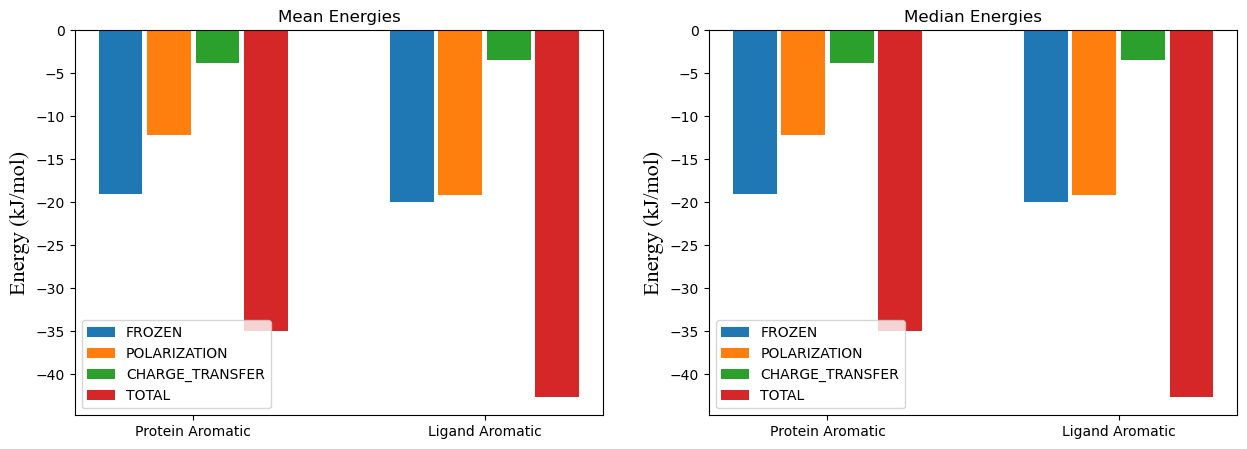

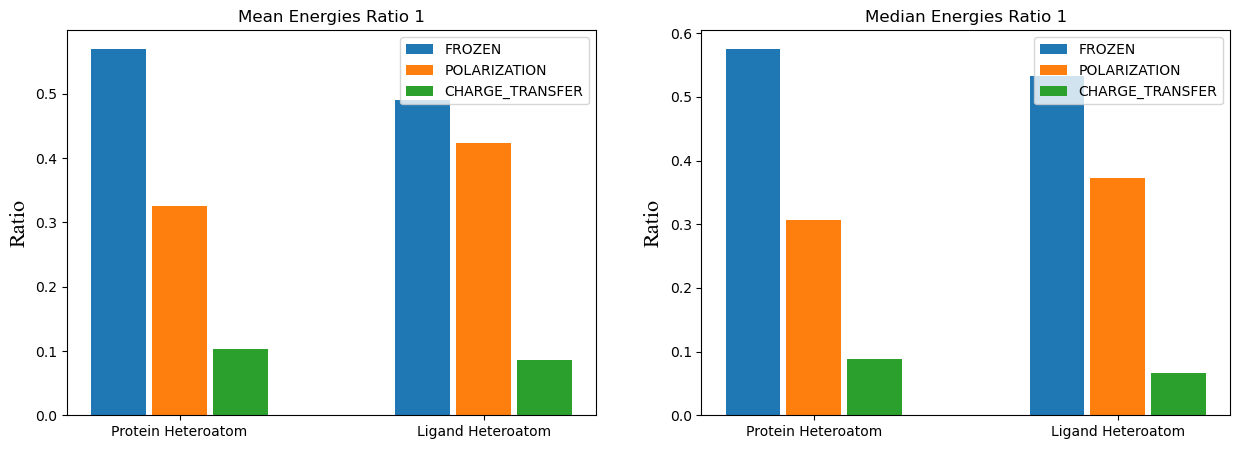

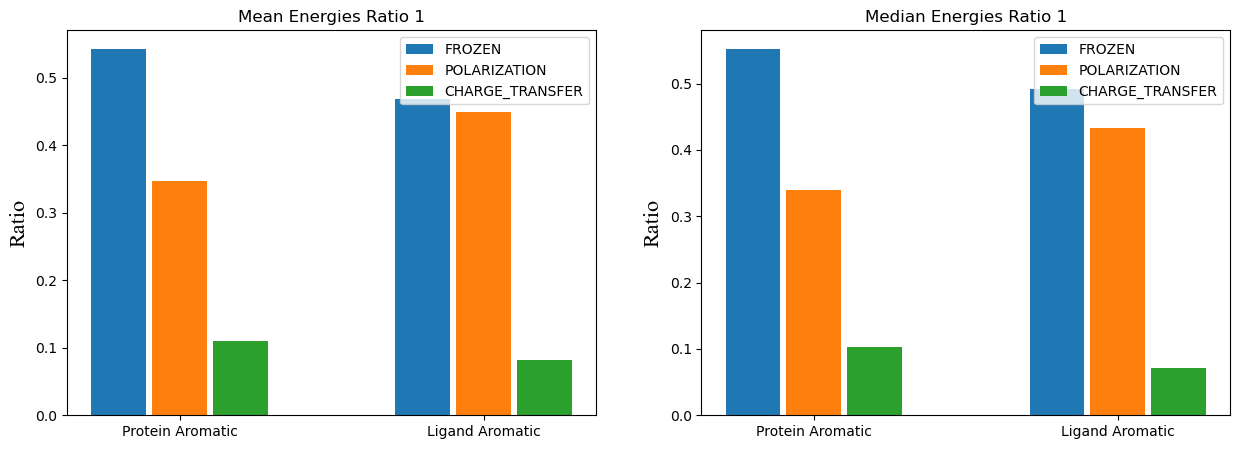

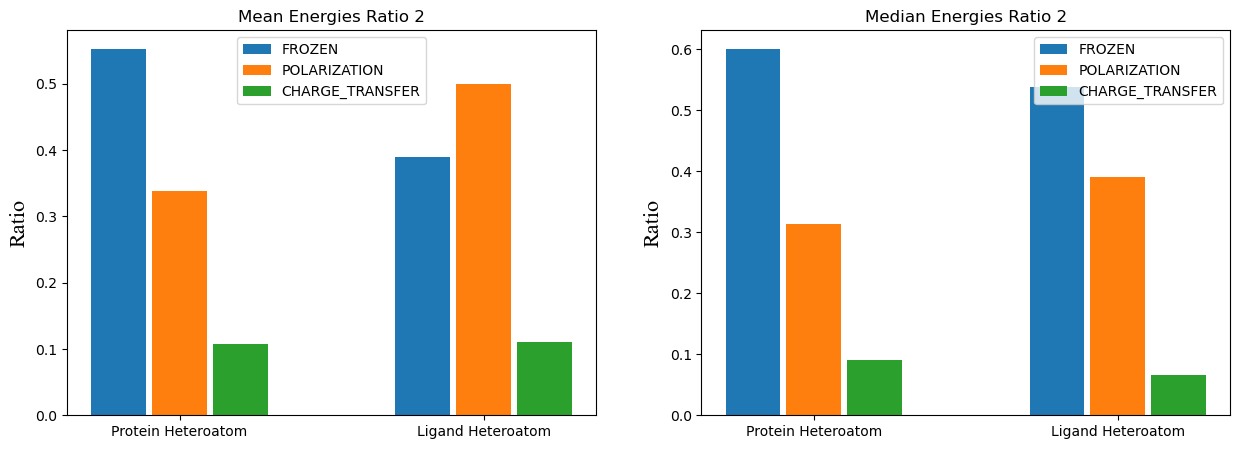

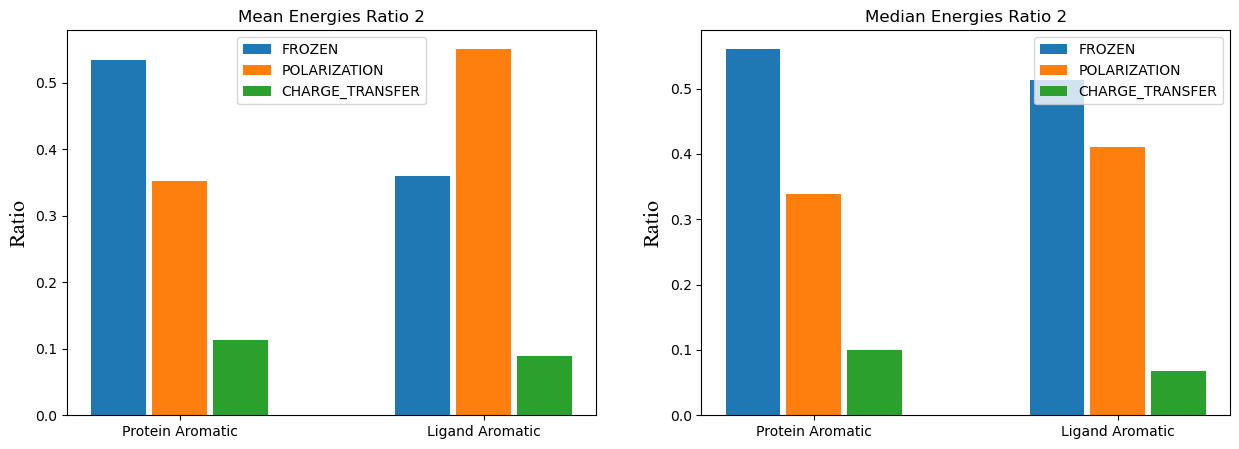

In [27]:
dfs_aromatic = [df_aromatic_prot, df_aromatic_lig]
dfs_hetratom = [df_hetratom_prot, df_hetratom_lig]
labels_aromatic = ['Protein Aromatic', 'Ligand Aromatic']
labels_hetratom = ['Protein Heteroatom', 'Ligand Heteroatom']

items = [
    'FROZEN', 
    # 'CLS_ELEC', 
    # 'MOD_PAULI', 
    # 'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]

print(f'len: {list(map(len, dfs_hetratom))}')
print(f'len: {list(map(len, dfs_aromatic))}')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot('bar', (labels_hetratom, items), dfs_hetratom, axes[0], median=False)
axes[0].set_title('Mean Energies')
plot('bar', (labels_hetratom, items), dfs_hetratom, axes[1])
axes[1].set_title('Median Energies')


fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot('bar', (labels_aromatic, items), dfs_aromatic, axes[0], median=False)
axes[0].set_title('Mean Energies')
plot('bar', (labels_aromatic, items), dfs_aromatic, axes[1])
axes[1].set_title('Median Energies')

items = [
    'FROZEN', 
    # 'CLS_ELEC', 
    # 'MOD_PAULI', 
    # 'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    # 'TOTAL'
]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot('bar', (labels_hetratom, items), dfs_hetratom, axes[0], ratio1=True)
axes[0].set_title('Mean Energies Ratio 1')
plot('bar', (labels_hetratom, items), dfs_hetratom, axes[1], median=True, ratio1=True)
axes[1].set_title('Median Energies Ratio 1')


fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot('bar', (labels_aromatic, items), dfs_aromatic, axes[0], ratio1=True)
axes[0].set_title('Mean Energies Ratio 1')
plot('bar', (labels_aromatic, items), dfs_aromatic, axes[1], median=True, ratio1=True)
axes[1].set_title('Median Energies Ratio 1')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot('bar', (labels_hetratom, items), dfs_hetratom, axes[0], ratio2=True)
axes[0].set_title('Mean Energies Ratio 2')
plot('bar', (labels_hetratom, items), dfs_hetratom, axes[1], median=True, ratio2=True)
axes[1].set_title('Median Energies Ratio 2')
plt.savefig("Visualizations/bar_heteroatom.png")


fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot('bar', (labels_aromatic, items), dfs_aromatic, axes[0], ratio2=True)
axes[0].set_title('Mean Energies Ratio 2')
plot('bar', (labels_aromatic, items), dfs_aromatic, axes[1], median=True, ratio2=True)
axes[1].set_title('Median Energies Ratio 2')
plt.savefig("Visualizations/bar_aromatic.slide.png")

# Tyrosine H-Bonding?

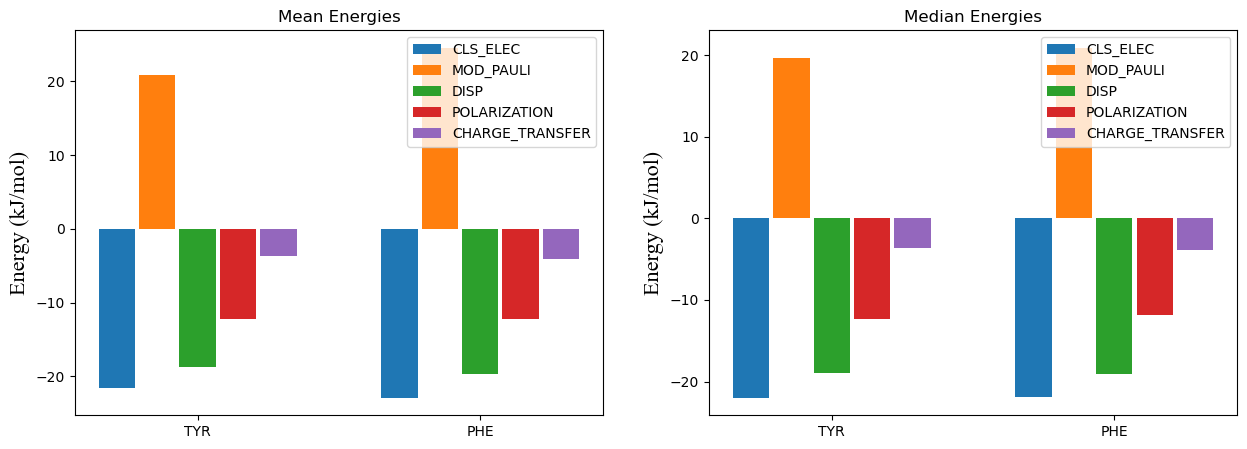

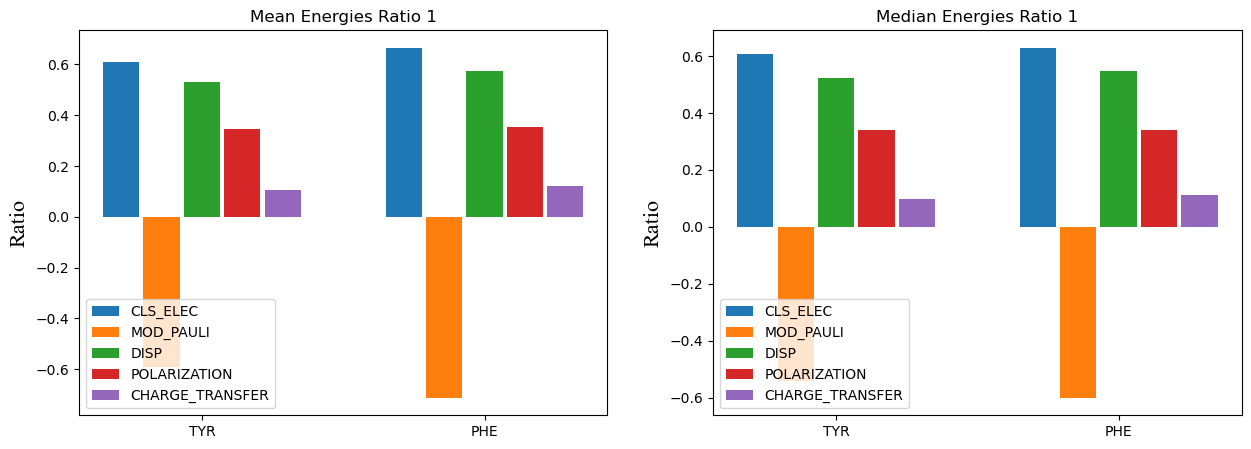

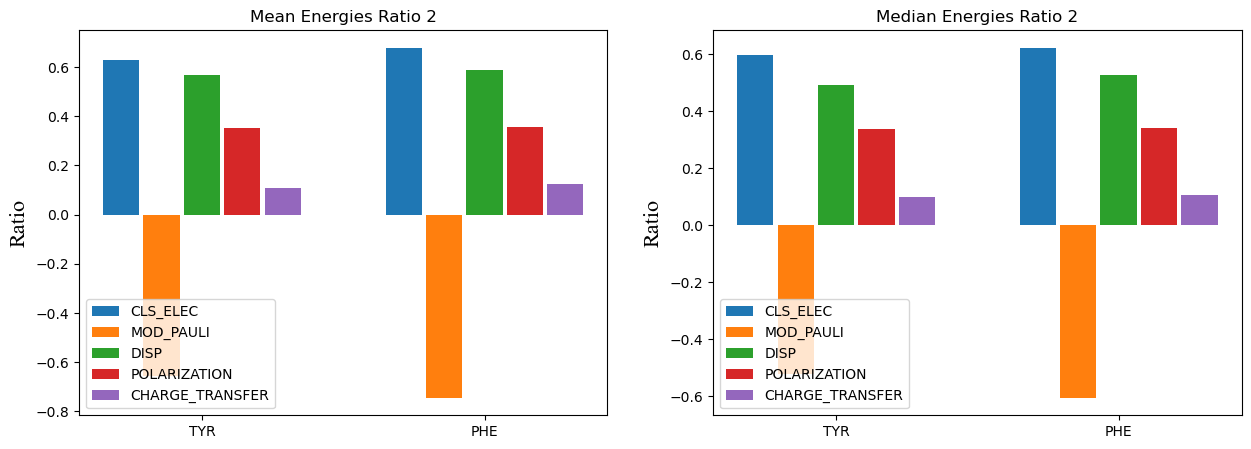

In [20]:
dfTYR = df.query("restype == 'TYR'")
dfPHE = df.query("restype == 'PHE'")

dfs = [dfTYR, dfPHE]
labels = ['TYR', 'PHE']

items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    # 'TOTAL'
]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot('bar', (labels, items), dfs, axes[0])
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), dfs, axes[1], median=True)
axes[1].set_title('Median Energies')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot('bar', (labels, items), dfs, axes[0], ratio1=True)
axes[0].set_title('Mean Energies Ratio 1')
plot('bar', (labels, items), dfs, axes[1], median=True, ratio1=True)
axes[1].set_title('Median Energies Ratio 1')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot('bar', (labels, items), dfs, axes[0], ratio2=True)
axes[0].set_title('Mean Energies Ratio 2')
plot('bar', (labels, items), dfs, axes[1], median=True, ratio2=True)
axes[1].set_title('Median Energies Ratio 2')
plt.savefig("Visualizations/TYR_PH.slide.png")